# 05 — Modelleme

Girdi: `data/processed/arac_temiz_v3.csv` (`python src/temizle.py` ile üretilir).
Çıktı: `reports/model_sonuclari.csv`, `reports/sehir_karsilastirma.csv`, `models/lgbm_model.txt` (git dışı).

Araştırma sorusu 2: Hangi model fiyatı en düşük hatayla tahmin ediyor? Soru 4'ün model tarafı da burada (şehirli/şehirsiz model).

**Kurulum:** Hedef `log_price`. Rastgele %80 eğitim / %20 test (tohum 42); veri tek zaman kesiti olduğu için zamana göre bölme gerekmiyor.
Test kümesine yalnızca son değerlendirmede dokunulur; LightGBM'in erken durdurması eğitim kümesinden ayrılan %10'luk doğrulama kümesiyle yapılır.

In [1]:
import sys, time, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

sns.set_theme(style="whitegrid")
TOHUM = 42
ROOT = Path("..")

# Özellik listeleri ve türetme kodu uygulama ile ortak: src/ozellikler.py
sys.path.insert(0, str(ROOT / "src"))
from ozellikler import KAT, SAY, REFERANS_YILI, model_ozellikleri, lgbm_girdisi

df = model_ozellikleri(pd.read_csv(ROOT / "data/processed/arac_temiz_v3.csv"))

egitim, test = train_test_split(df, test_size=0.2, random_state=TOHUM)
print(f"Eğitim: {len(egitim):,}  Test: {len(test):,}")
print("Testte eğitimde hiç görülmeyen varyant:", (~test["variant"].isin(egitim["variant"])).sum())

Eğitim: 200,764  Test: 50,191


Testte eğitimde hiç görülmeyen varyant: 2


### Sızıntı kontrolü
Aynı araç küçük km farkıyla iki kez ilana konmuşsa ve biri eğitimde, biri testte ise skor yapay olarak iyi görünür.
Testte, eğitimde aynı marka-model-varyant-yıl-renk-şehir-**fiyat** ve km farkı ≤ 2.000 olan bir eşi bulunan ilanları sayıyoruz.

In [2]:
k = ["brand", "model", "variant", "year", "color", "city", "price"]
es = test.reset_index().merge(egitim[k + ["km"]], on=k, suffixes=("", "_egitim"))
es = es[(es["km"] - es["km_egitim"]).abs() <= 2000]
print(f"Yakın kopya test ilanı: {es['index'].nunique()} (%{es['index'].nunique() / len(test) * 100:.2f})")

Yakın kopya test ilanı: 96 (%0.19)


## Ölçütler
Log ölçekte MAE, RMSE, R²; TL ölçeğinde (tahmin = e^log tahmin) MAE, RMSE, R², ortalama ve ortanca yüzde hata (MAPE, MdAPE).
e^tahmin, log ölçekte ortalamayı hedeflediği için TL'de ortancaya yakın bir tahmindir; bu yüzden MdAPE en yorumlanabilir ölçüttür.

In [3]:
def olc(ad, tahmin_log, sure, veri=None):
    veri = test if veri is None else veri
    y, tl = veri["log_price"].values, veri["price"].values
    t_tl = np.exp(tahmin_log)
    return {"model": ad,
            "MAE_log": mean_absolute_error(y, tahmin_log),
            "RMSE_log": np.sqrt(mean_squared_error(y, tahmin_log)),
            "R2_log": r2_score(y, tahmin_log),
            "MAE_TL": mean_absolute_error(tl, t_tl),
            "RMSE_TL": np.sqrt(mean_squared_error(tl, t_tl)),
            "R2_TL": r2_score(tl, t_tl),
            "MAPE_%": np.mean(np.abs(t_tl - tl) / tl) * 100,
            "MdAPE_%": np.median(np.abs(t_tl - tl) / tl) * 100,
            "egitim_sn": sure}

sonuclar = []
tahminler = {}

## 1. Taban çizgisi: yalnızca model yılı
Her model yılı için eğitim kümesindeki ortanca log fiyat. Diğer modellerin ne kadar katkı sağladığını göstermek için.

In [4]:
t = time.time()
yil_medyan = egitim.groupby("year")["log_price"].median()
tahminler["Taban (yıl)"] = test["year"].map(yil_medyan).values
sonuclar.append(olc("Taban (yıl)", tahminler["Taban (yıl)"], time.time() - t))

## 2. Doğrusal regresyon (Ridge)
Kategoriler one-hot (5'ten az görülen kategoriler tek "seyrek" sütunda), yaş ve yaş², km (10 bin), bayraklar.
Varyant modelin, model de markanın içinde yer aldığı için sütunlar arasında tam doğrusallık var; bu yüzden düz EKK yerine
küçük bir cezalı (Ridge, α = 1) model kullanıldı. Motor hacmi boşsa eğitim ortancasıyla dolduruldu ve `hacim_yok` bayrağı eklendi.

In [5]:
hacim_ortanca = egitim["motor_hacmi"].median()

def X_dogrusal(d):
    return d[KAT].assign(yas=d["yas"], yas2=d["yas"] ** 2, km10k=d["km"] / 10_000,
                         km_kirpildi=d["km_kirpildi"], hacim_yok=d["hacim_yok"],
                         motor_hacmi=d["motor_hacmi"].fillna(hacim_ortanca))

t = time.time()
dogrusal = make_pipeline(
    ColumnTransformer([("kat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), KAT)], remainder="passthrough"),
    Ridge(alpha=1.0))
dogrusal.fit(X_dogrusal(egitim), egitim["log_price"])
tahminler["Doğrusal (Ridge)"] = dogrusal.predict(X_dogrusal(test))
sonuclar.append(olc("Doğrusal (Ridge)", tahminler["Doğrusal (Ridge)"], time.time() - t))

## 3. Random Forest
Kategoriler sıra numarasına çevrildi (ağaçlar için yeterli; 2 bin varyantı one-hot yapmak çok yavaş olurdu). Motor hacmi boşsa −1.
200 ağaç, yaprakta en az 2 gözlem, her bölmede özelliklerin yarısı.

In [6]:
kodlayici = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(egitim[KAT])

def X_sira(d):
    return np.column_stack([kodlayici.transform(d[KAT]), d[SAY].fillna(-1).values])

t = time.time()
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, max_features=0.5, n_jobs=-1, random_state=TOHUM)
rf.fit(X_sira(egitim), egitim["log_price"])
tahminler["Random Forest"] = rf.predict(X_sira(test))
sonuclar.append(olc("Random Forest", tahminler["Random Forest"], time.time() - t))

## 4. LightGBM
Kategoriler LightGBM'e doğrudan kategorik olarak verilir; motor hacmi boşluğunu kendisi işler.
Erken durdurma için eğitim kümesinin %10'u doğrulamaya ayrıldı.

Ayar seçimi (doğrulama kümesinde, test kullanılmadan denendi; MAE_log):
63 yaprak/0,05 → 0,0826 · 127/0,05 → 0,0820 · 255/0,03 → 0,0814 · 511/0,03 → 0,0812 · 255/0,05, min_child 50 → 0,0815.
Farklar çok küçük; **255 yaprak, öğrenme oranı 0,03** seçildi. ⚠ Tezde bu küçük ayar denemesini yöntem bölümünde belirt.

In [7]:
KATEGORILER = {k: sorted(egitim[k].unique()) for k in KAT}

def X_lgbm(d, ozellikler=KAT + SAY):
    return lgbm_girdisi(d, KATEGORILER, ozellikler)

LGBM_AYAR = dict(n_estimators=10_000, learning_rate=0.03, num_leaves=255, min_child_samples=20,
                 subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=TOHUM)
egitim_ic, dogrulama = train_test_split(egitim, test_size=0.1, random_state=TOHUM)

def lgbm_egit(ozellikler):
    m = lgb.LGBMRegressor(**LGBM_AYAR)
    m.fit(X_lgbm(egitim_ic, ozellikler), egitim_ic["log_price"],
          eval_X=(X_lgbm(dogrulama, ozellikler),), eval_y=(dogrulama["log_price"],),
          callbacks=[lgb.early_stopping(200, verbose=False)])
    return m

t = time.time()
lgbm = lgbm_egit(KAT + SAY)
print("En iyi iterasyon:", lgbm.best_iteration_)
tahminler["LightGBM"] = lgbm.predict(X_lgbm(test))
sonuclar.append(olc("LightGBM", tahminler["LightGBM"], time.time() - t))

En iyi iterasyon: 347


## Sonuç tablosu (test kümesi)

In [8]:
tablo = pd.DataFrame(sonuclar).set_index("model")
(ROOT / "reports").mkdir(exist_ok=True)
tablo.round(4).to_csv(ROOT / "reports/model_sonuclari.csv")
gosterim = tablo.copy()
for s in ["MAE_TL", "RMSE_TL"]:
    gosterim[s] = gosterim[s].map("{:,.0f}".format)
display(gosterim.round(3))

,MAE_log,RMSE_log,R2_log,MAE_TL,RMSE_TL,R2_TL,MAPE_%,MdAPE_%,egitim_sn
model,,,,,,,,,
Taban (yıl),0.318,0.427,0.549,"385,386","766,719",0.238,30.219,24.516,0.006
Doğrusal (Ridge),0.111,0.150,0.944,"121,870","263,459",0.910,11.216,8.444,1.693
Random Forest,0.086,0.120,0.965,"83,750","149,739",0.971,8.752,6.264,13.658
LightGBM,0.082,0.114,0.968,"79,578","142,802",0.974,8.321,5.931,9.156


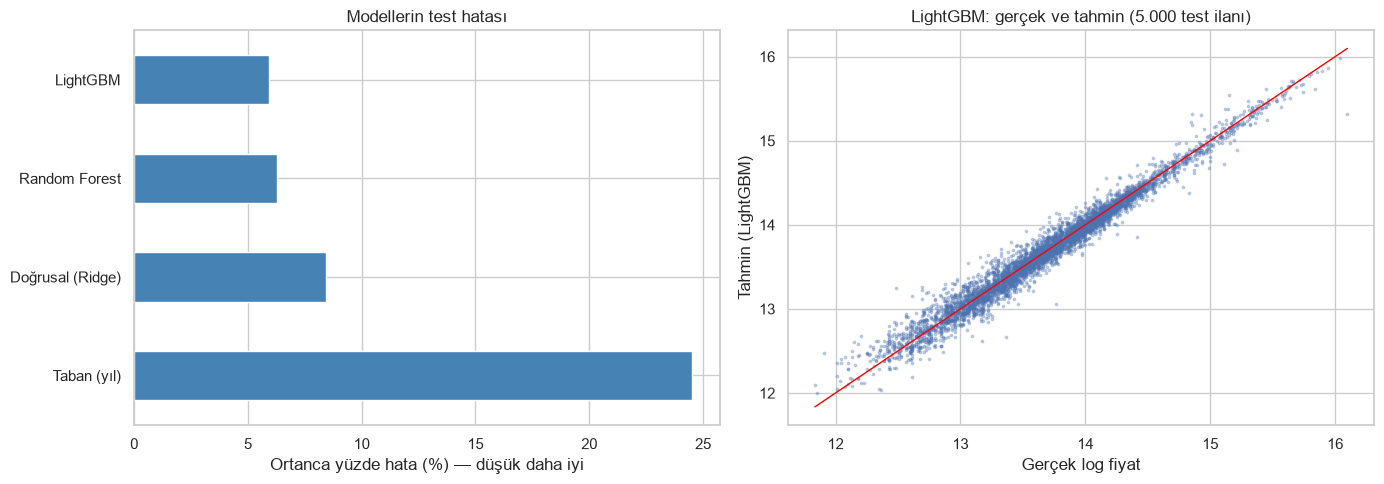

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tablo["MdAPE_%"].plot.barh(ax=axes[0], color="steelblue")
axes[0].set_xlabel("Ortanca yüzde hata (%) — düşük daha iyi"); axes[0].set_ylabel("")
axes[0].set_title("Modellerin test hatası")
ornek = test.assign(tahmin=tahminler["LightGBM"]).sample(5000, random_state=TOHUM)
axes[1].scatter(ornek["log_price"], ornek["tahmin"], s=3, alpha=0.3)
s = [ornek["log_price"].min(), ornek["log_price"].max()]
axes[1].plot(s, s, color="red", lw=1)
axes[1].set_xlabel("Gerçek log fiyat"); axes[1].set_ylabel("Tahmin (LightGBM)")
axes[1].set_title("LightGBM: gerçek ve tahmin (5.000 test ilanı)")
plt.tight_layout(); plt.show()

## Hata analizi (LightGBM)
Model hangi segmentlerde zorlanıyor? Fiyat dilimine, yakıt tipine ve markaya göre ortanca yüzde hata.

In [10]:
h = test.assign(ape=np.abs(np.exp(tahminler["LightGBM"]) - test["price"]) / test["price"] * 100)
h["fiyat_dilimi"] = pd.qcut(h["price"], 5, labels=["En ucuz %20", "2.", "3.", "4.", "En pahalı %20"])
for kol in ["fiyat_dilimi", "yakit_tipi"]:
    display(h.groupby(kol, observed=True)["ape"].agg(ilan="size", MdAPE_yuzde="median").round(2))
display(h.groupby("brand")["ape"].agg(ilan="size", MdAPE_yuzde="median").query("ilan >= 1000")
          .sort_values("MdAPE_yuzde").round(2))

,ilan,MdAPE_yuzde
fiyat_dilimi,,
En ucuz %20,10052,8.95
2.,10025,6.95
3.,10039,5.60
4.,10048,4.83
En pahalı %20,10027,4.67


,ilan,MdAPE_yuzde
yakit_tipi,,
Benzin,13783,5.08
Bilinmiyor,13244,7.00
Dizel,21941,6.12
Hibrit/Elektrik,459,3.68
LPG,764,3.85


,ilan,MdAPE_yuzde
brand,,
honda,1759,5.10
mercedes,2823,5.22
citroen,1487,5.29
fiat,4781,5.38
toyota,2427,5.39
bmw,3556,5.43
skoda,1812,5.57
renault,7180,5.61
audi,2151,5.70


## Soru 4 (model tarafı): Şehir tahmine katkı sağlıyor mu?
Aynı LightGBM ayarlarıyla şehir sütunu çıkarılarak yeniden eğitildi; iki modelin test hatası karşılaştırılıyor.

In [11]:
t = time.time()
ozellik_sehirsiz = [o for o in KAT + SAY if o != "city"]
lgbm_sehirsiz = lgbm_egit(ozellik_sehirsiz)
p = lgbm_sehirsiz.predict(X_lgbm(test, ozellik_sehirsiz))
sehir_tablo = pd.DataFrame([olc("LightGBM (şehirli)", tahminler["LightGBM"], np.nan),
                            olc("LightGBM (şehirsiz)", p, time.time() - t)]).set_index("model")
sehir_tablo.round(4).to_csv(ROOT / "reports/sehir_karsilastirma.csv")
display(sehir_tablo[["MAE_log", "RMSE_log", "R2_log", "MdAPE_%"]].round(4))
fark = sehir_tablo.loc["LightGBM (şehirsiz)", "MAE_log"] / sehir_tablo.loc["LightGBM (şehirli)", "MAE_log"] - 1
print(f"Şehir çıkarılınca MAE_log %{fark * 100:.1f} artıyor.")

,MAE_log,RMSE_log,R2_log,MdAPE_%
model,,,,
LightGBM (şehirli),0.0817,0.1144,0.9677,5.9307
LightGBM (şehirsiz),0.0841,0.1173,0.9660,6.1298


Şehir çıkarılınca MAE_log %2.9 artıyor.


## Modeli ve uygulama dosyalarını kaydet
- `lgbm_model.txt`: model · `lgbm_meta.json`: kategori listeleri ve tahmin aralığı · `katalog.csv`: uygulamadaki marka → model → varyant seçimleri.
- **Tahmin aralığı:** Test kümesindeki log hataların %10 ve %90 yüzdelikleri. Uygulamada "tahmin × e^q10 … tahmin × e^q90" olarak gösterilir;
  test ilanlarının %80'inin gerçek fiyatı bu aralığa düşer. Aralık tüm araçlar için aynı genişliktedir (basitleştirme; ucuz araçlarda hata daha büyük).

In [12]:
(ROOT / "models").mkdir(exist_ok=True)
lgbm.booster_.save_model(ROOT / "models/lgbm_model.txt", num_iteration=lgbm.best_iteration_)

hata = test["log_price"].values - tahminler["LightGBM"]
q10, q90 = np.quantile(hata, [0.10, 0.90])
kapsama = np.mean((hata >= q10) & (hata <= q90))
print(f"Tahmin aralığı: tahmin × [{np.exp(q10):.3f}, {np.exp(q90):.3f}]  (test kapsaması %{kapsama * 100:.0f})")

json.dump({"kategoriler": KATEGORILER, "ozellikler": KAT + SAY, "yas_referans_yili": REFERANS_YILI,
           "aralik_log": [float(q10), float(q90)],
           "test_mdape": float(tablo.loc["LightGBM", "MdAPE_%"])},
          open(ROOT / "models/lgbm_meta.json", "w"), ensure_ascii=False)

# Uygulama seçim listesi: yalnızca eğitimde görülen varyantlar (model bunları tanır)
katalog = (egitim.groupby(["brand", "model", "variant"])
           .agg(ilan=("price", "size"), yil_min=("year", "min"), yil_max=("year", "max"),
                yakit_tipi=("yakit_tipi", "first"), motor_hacmi=("motor_hacmi", "first"))
           .reset_index())
katalog.to_csv(ROOT / "models/katalog.csv", index=False)
print(f"Kaydedildi: models/lgbm_model.txt, models/lgbm_meta.json, models/katalog.csv ({len(katalog):,} varyant)")

Tahmin aralığı: tahmin × [0.875, 1.131]  (test kapsaması %80)
Kaydedildi: models/lgbm_model.txt, models/lgbm_meta.json, models/katalog.csv (2,702 varyant)


## Bulgular (taslak — kendi sözlerinle yaz)
Aşağıdaki sayılar notebook çalıştırıldıktan sonra tablodan doldurulmalı; yorum senin olmalı.
- Model karşılaştırması (Soru 2): …
- Şehir (Soru 4): …
- Hata analizi: …

⚠ **Sınırlılıklar:** Test hatası rastgele bölünmüş aynı dönem verisinde ölçüldü; başka bir aya genellenebilirlik test edilmedi.
Hiperparametre araması küçük tutuldu. Random Forest ve Ridge için ayar denemesi yapılmadı (varsayılana yakın makul değerler).